# LAB 01
## Cài đặt và so sánh hiệu năng giữa các hàm tự cài đặt sử dụng numpy và thư viện CV2


In [26]:
# Tải về ảnh sample
!curl -O https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg -o Lenna.jpg 2>/dev/null || curl -O http://www.ess.ic.kanagawa-it.ac.jp/std_img/colorimage/Lenna.jpg

# Cài đặt thư viện opencv (nếu chưa có)
!pip install opencv-python opencv-contrib-python matplotlib

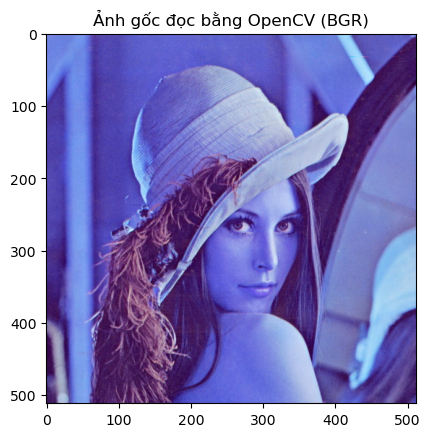

In [27]:
import numpy as np
import cv2
%matplotlib inline
import matplotlib.pyplot as plt

# cv2.imread(filename[, flags]): hàm tải ảnh lên
# filename: tên file ảnh
# flags: tham số tuỳ chọn hiển thị ảnh, giá trị mặc định là IMREAD_COLOR
######
# cv2.IMREAD_COLOR sẽ được giải mã theo thứ tự B G R, vì vậy khi hiển thị sẽ bị sai màu
img = cv2.imread('Lenna.jpg', cv2.IMREAD_COLOR)
if img is not None:
    plt.imshow(img)
    plt.title("Ảnh gốc đọc bằng OpenCV (BGR)")
    plt.show()
else:
    print("Chưa tìm thấy file Lenna.jpg, hãy chạy cell tải ảnh ở trên!")

In [28]:
# Phần 1 Color Transformation

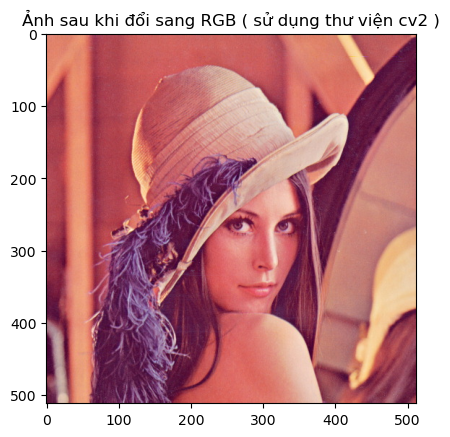

Kích thước ảnh (H x W x C): (512, 512, 3)


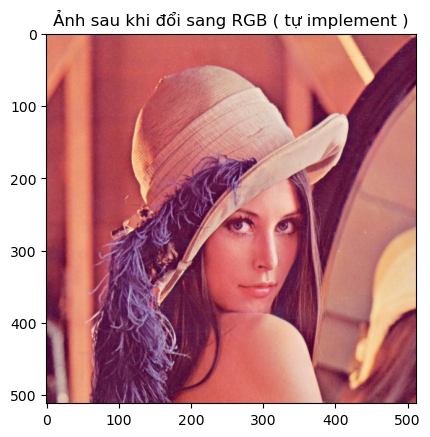

Kích thước ảnh (H x W x C): (512, 512, 3)


In [29]:
# Sử dụng cvtColor để chuyển từ BGR sang RGB
if img is not None:
    img_new = img.copy()
    img_new = cv2.cvtColor(img_new, cv2.COLOR_BGR2RGB)
    plt.imshow(img_new)
    plt.title("Ảnh sau khi đổi sang RGB ( sử dụng thư viện cv2 )")
    plt.show()
    print("Kích thước ảnh (H x W x C):", img_new.shape)
if img is not None:
    img_new = img.copy()
    img_new = img_new[:,:,[2, 1, 0]]
    
    plt.imshow(img_new)
    plt.title("Ảnh sau khi đổi sang RGB ( tự implement )")
    plt.show()
    print("Kích thước ảnh (H x W x C):", img_new.shape)


In [30]:
# Change the image color to RGB for better visualization
if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

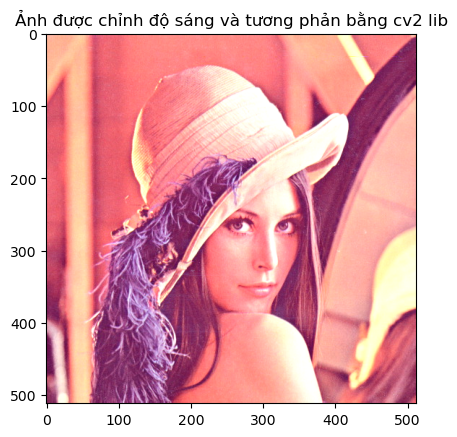

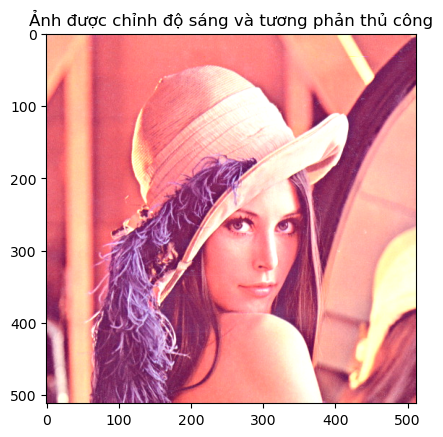

In [31]:
# Brightness and contrast adjustment

# Constant for adjusting contrast and brightness
a = 1.3   # Change it to 1 if just want to change brightness
b = 10    # Change it to 0 if just want to change contrast

# Using opencv lib
result = cv2.convertScaleAbs(img, alpha=a, beta=b)
plt.imshow(result)
plt.title("Ảnh được chỉnh độ sáng và tương phản bằng cv2 lib")
plt.show()

# Thủ công
temp = img.astype(np.float32)
temp = temp * a + b
temp = temp.astype(np.int32)
temp = np.clip(temp, 0, 255)

plt.imshow(temp)
plt.title("Ảnh được chỉnh độ sáng và tương phản thủ công")
plt.show()




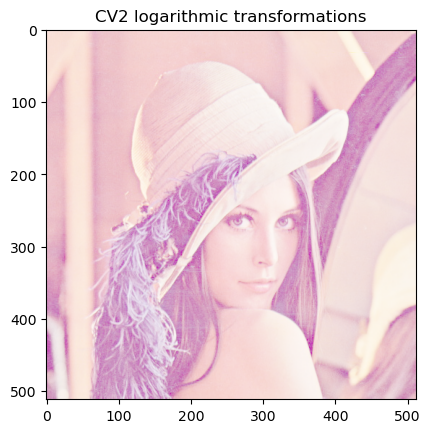

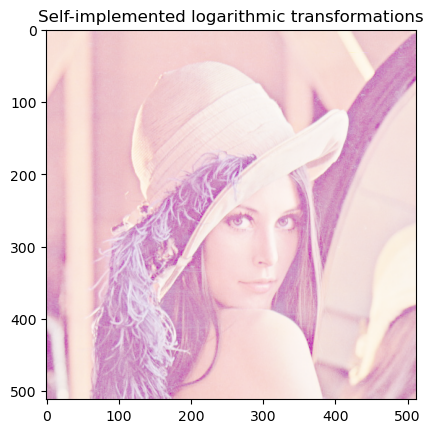

In [32]:
# Non-linear: Logarithmic transformations.

# Cv2 lib
arr = np.arange(256, dtype=np.float32)

c = 255 / np.log(1 + np.max(img.astype(np.float32)))
lut = np.clip(c * np.log(1 + arr), 0, 255).astype(np.uint8)

result = cv2.LUT(img, lut)
plt.imshow(result)
plt.title("CV2 logarithmic transformations")
plt.show()

# Self implement
temp = img.astype(np.float32)
c = 255 / np.log(1 + np.max(temp))
temp = c * np.log(1 + temp)
plt.imshow(temp.astype(np.int32))
plt.title("Self-implemented logarithmic transformations")
plt.show()



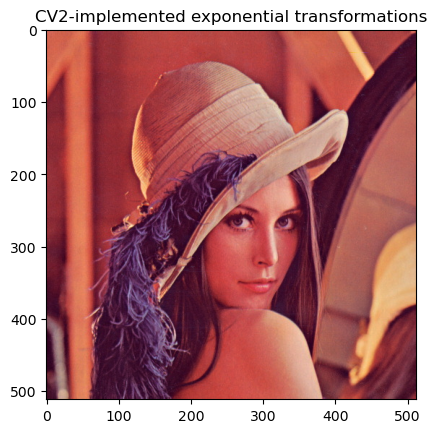

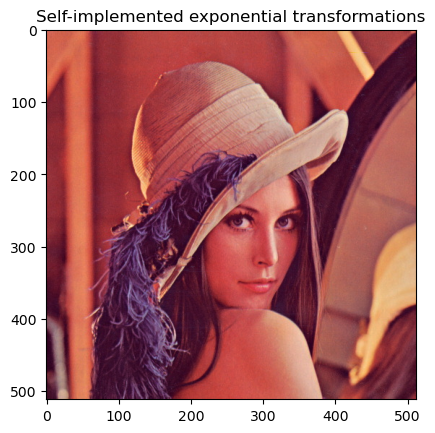

In [33]:
# Exponential transformations.

# hệ số gamma 
y = 1

arr = np.arange(256, dtype= np.float32)
c = 255 / (np.exp(y) - 1)
norm = arr / 255.0
lut = (c * (np.exp(y * norm) - 1)).astype(np.uint8)

result = cv2.LUT(img, lut)
plt.imshow(result)
plt.title("CV2-implemented exponential transformations")
plt.show()

# Self-implement
c = 255 / (np.exp(y) - 1)
temp = img.astype(np.float32)
norm = temp / 255.0
temp = c * (np.exp(y * norm) - 1)
plt.imshow(temp.astype(np.uint8))
plt.title("Self-implemented exponential transformations")
plt.show()



262144


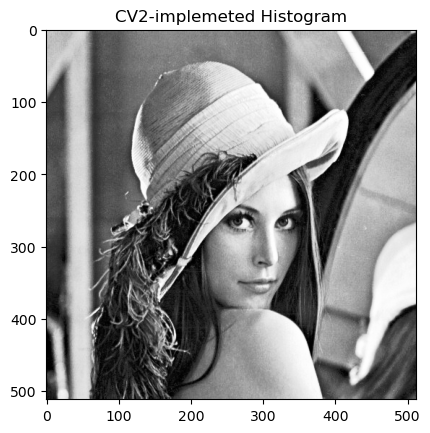

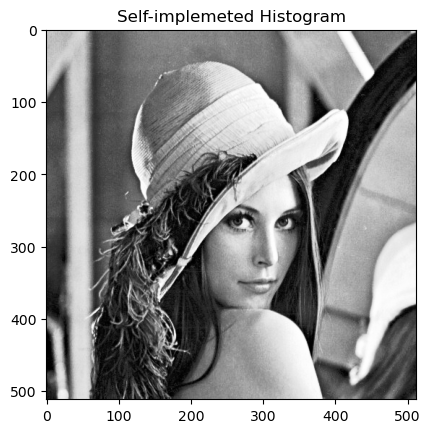

In [34]:
# PDF-based: Histogram equalization
# Gray=0.2989×𝑅+0.5870×𝐺+0.1140×𝐵

R = img[:,:,0].copy()
G = img[:,:,1].copy()
B = img[:,:,2].copy()
total_pixel = img.shape[0] * img.shape[1]
print(total_pixel)

img_gray =  (0.2989 * R + 0.5870 * G + 0.1140 * B).astype(np.uint8)

# CV2
cv2_result = cv2.equalizeHist(img_gray)
plt.imshow(cv2_result, cmap='gray')
plt.title("CV2-implemeted Histogram")
plt.show()

# thủ công


hist = np.bincount(img_gray.flatten(), minlength=256)
cdf = np.cumsum(hist)
mapping = np.round(255 * cdf / total_pixel).astype(np.uint8)
img_new = mapping[img_gray]
plt.imshow(img_new, cmap='gray')
plt.title("Self-implemeted Histogram")
plt.show()



262144


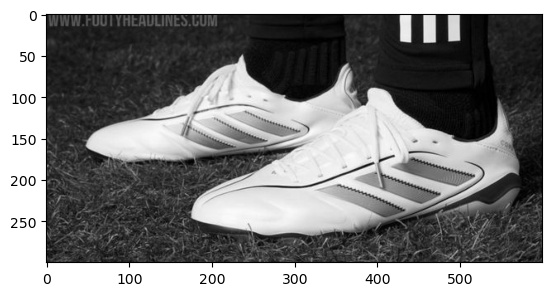

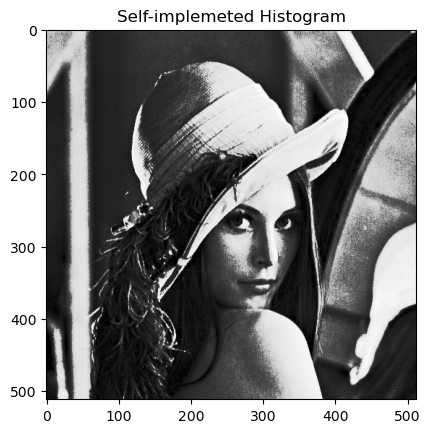

In [35]:
# histogram specification

ref_img = cv2.imread('adidas.jpg', cv2.IMREAD_COLOR)
ref_img = cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB)

# Bien src_img thanh gray
R = img[:,:,0].copy()
G = img[:,:,1].copy()
B = img[:,:,2].copy()
total_pixel = img.shape[0] * img.shape[1]
print(total_pixel)

img_gray =  (0.2989 * R + 0.5870 * G + 0.1140 * B).astype(np.uint8)

# Bien ref_img thanh gray

R_ref = ref_img[:,:,0].copy()
G_ref = ref_img[:,:,1].copy()
B_ref = ref_img[:,:,2].copy()
total_pixel = ref_img.shape[0] * ref_img.shape[1]

ref_gray =  (0.2989 * R_ref + 0.5870 * G_ref + 0.1140 * B_ref).astype(np.uint8)

plt.imshow(ref_gray, cmap='gray')
plt.show()


# Thủ công
# Calculate hist src
hist = np.bincount(img_gray.flatten(), minlength=256)
cdf = np.cumsum(hist)
cdf_src = cdf / img_gray.size
# Calculate hist ref
hist_ref = np.bincount(ref_gray.flatten(), minlength=256)
cdf_ref = np.cumsum(hist_ref) / ref_gray.size

np.zeros(256, dtype=np.uint8)
for r in range(256):
    z = np.argmin(np.abs(cdf_ref - cdf_src[r]))
    mapping[r] = z

img_new = mapping[img_gray]


plt.imshow(img_new, cmap='gray')
plt.title("Self-implemeted Histogram")
plt.show()

# CV2
# Tái sử dụng hist ở 


## 2. Geometric Transformation

### 2.1 Interpolation: Nearest-Neighbor và Linear (Bilinear) Interpolation

Khi thay đổi kích thước (resize) hoặc biến đổi hình học, tọa độ ánh xạ ngược thường rơi vào vị trí **không nguyên**. Ta cần phép nội suy (Interpolation) để tính giá trị pixel:
- **Nearest-Neighbor**: Lấy giá trị của pixel lân cận gần nhất (nhanh, giữ nguyên giá trị gốc nhưng dễ bị răng cưa / vỡ hạt).
- **Bilinear (Linear 2D)**: Nội suy tuyến tính từ 4 pixel lân cận gần nhất theo trọng số khoảng cách (ảnh mượt hơn).

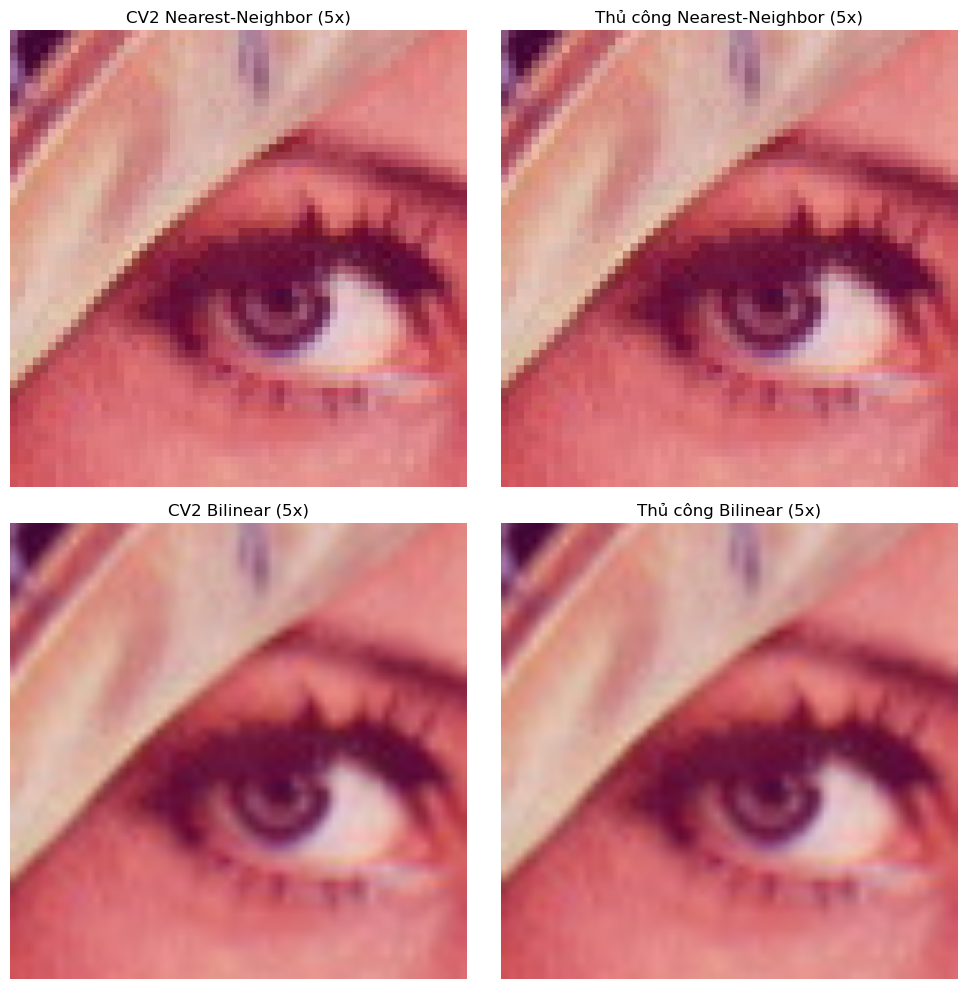

MSE Nearest-Neighbor (CV2 vs Thủ công): 0.0
MSE Bilinear (CV2 vs Thủ công): 0.099755555


In [36]:
# Self-implemented Interpolation: Nearest-Neighbor & Bilinear
def nearest_neighbor_resize(image, new_h, new_w):
    h, w = image.shape[:2]
    y_src = np.clip(np.round((np.arange(new_h) + 0.5) * (h / new_h) - 0.5).astype(int), 0, h - 1)
    x_src = np.clip(np.round((np.arange(new_w) + 0.5) * (w / new_w) - 0.5).astype(int), 0, w - 1)
    return image[y_src[:, None], x_src[None, :]]

def bilinear_resize(image, new_h, new_w):
    h, w = image.shape[:2]
    y = np.clip((np.arange(new_h) + 0.5) * (h / new_h) - 0.5, 0, h - 1)
    x = np.clip((np.arange(new_w) + 0.5) * (w / new_w) - 0.5, 0, w - 1)

    y0 = np.floor(y).astype(int)
    x0 = np.floor(x).astype(int)
    y1 = np.minimum(y0 + 1, h - 1)
    x1 = np.minimum(x0 + 1, w - 1)

    dy = (y - y0)[:, None]
    dx = (x - x0)[None, :]
    if image.ndim == 3:
        dy = dy[:, :, None]
        dx = dx[:, :, None]

    img_f = image.astype(np.float32)
    Ia = img_f[y0[:, None], x0[None, :]]
    Ib = img_f[y1[:, None], x0[None, :]]
    Ic = img_f[y0[:, None], x1[None, :]]
    Id = img_f[y1[:, None], x1[None, :]]

    out = (1 - dy) * (1 - dx) * Ia + dy * (1 - dx) * Ib + (1 - dy) * dx * Ic + dy * dx * Id
    return np.clip(np.round(out), 0, 255).astype(image.dtype)

# Cắt một vùng nhỏ (vùng mắt) rồi phóng to 5 lần để thấy rõ sự khác biệt giữa 2 phép nội suy
crop = img[230:290, 230:290]
scale = 5
new_h, new_w = crop.shape[0] * scale, crop.shape[1] * scale

# OpenCV
cv_nn = cv2.resize(crop, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
cv_linear = cv2.resize(crop, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

# Thủ công
manual_nn = nearest_neighbor_resize(crop, new_h, new_w)
manual_linear = bilinear_resize(crop, new_h, new_w)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(cv_nn); axes[0, 0].set_title('CV2 Nearest-Neighbor (5x)'); axes[0, 0].axis('off')
axes[0, 1].imshow(manual_nn); axes[0, 1].set_title('Thủ công Nearest-Neighbor (5x)'); axes[0, 1].axis('off')
axes[1, 0].imshow(cv_linear); axes[1, 0].set_title('CV2 Bilinear (5x)'); axes[1, 0].axis('off')
axes[1, 1].imshow(manual_linear); axes[1, 1].set_title('Thủ công Bilinear (5x)'); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

print('MSE Nearest-Neighbor (CV2 vs Thủ công):', np.mean((cv_nn.astype(np.float32) - manual_nn.astype(np.float32)) ** 2))
print('MSE Bilinear (CV2 vs Thủ công):', np.mean((cv_linear.astype(np.float32) - manual_linear.astype(np.float32)) ** 2))

### 2.2 Affine Transformation Matrix: Translation, Rotation, Scaling, and Shearing

Biến đổi Affine sử dụng ma trận $M$ kích thước $2 \times 3$ (hoặc ma trận đồng nhất $3 \times 3$):
$$
\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = \begin{bmatrix} a & b & t_x \\ c & d & t_y \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}
$$
Để tránh xuất hiện các lỗ hổng (holes) trên ảnh đích, ta dùng **Inverse Mapping**: với mỗi pixel $(x', y')$ trên ảnh đích, tính ngược lại tọa độ $(x, y) = M^{-1} [x', y', 1]^T$ trên ảnh gốc rồi nội suy.

In [37]:
# Hàm warpAffine tự cài đặt (Inverse Mapping + Nearest-Neighbor / Bilinear)
def warp_affine_manual(image, M, dsize, interpolation='bilinear'):
    h, w = image.shape[:2]
    out_w, out_h = dsize

    M_3x3 = np.vstack([M.astype(np.float64), [0.0, 0.0, 1.0]])
    M_inv = np.linalg.inv(M_3x3)

    xs, ys = np.meshgrid(np.arange(out_w, dtype=np.float32), np.arange(out_h, dtype=np.float32))
    src_x = M_inv[0, 0] * xs + M_inv[0, 1] * ys + M_inv[0, 2]
    src_y = M_inv[1, 0] * xs + M_inv[1, 1] * ys + M_inv[1, 2]

    if interpolation == 'nearest':
        xi = np.round(src_x).astype(int)
        yi = np.round(src_y).astype(int)
        valid = (xi >= 0) & (xi < w) & (yi >= 0) & (yi < h)
        out = np.zeros((out_h, out_w) + image.shape[2:], dtype=image.dtype)
        out[valid] = image[yi[valid], xi[valid]]
        return out

    # Bilinear interpolation
    x0 = np.floor(src_x).astype(int)
    y0 = np.floor(src_y).astype(int)
    x1 = x0 + 1
    y1 = y0 + 1

    dx = src_x - x0
    dy = src_y - y0
    if image.ndim == 3:
        dx = dx[..., None]
        dy = dy[..., None]

    def sample(yy, xx):
        mask = (xx >= 0) & (xx < w) & (yy >= 0) & (yy < h)
        res = np.zeros((out_h, out_w) + image.shape[2:], dtype=np.float32)
        res[mask] = image[yy[mask], xx[mask]].astype(np.float32)
        return res

    out = (
        (1 - dy) * (1 - dx) * sample(y0, x0)
        + dy * (1 - dx) * sample(y1, x0)
        + (1 - dy) * dx * sample(y0, x1)
        + dy * dx * sample(y1, x1)
    )
    return np.clip(np.round(out), 0, 255).astype(image.dtype)

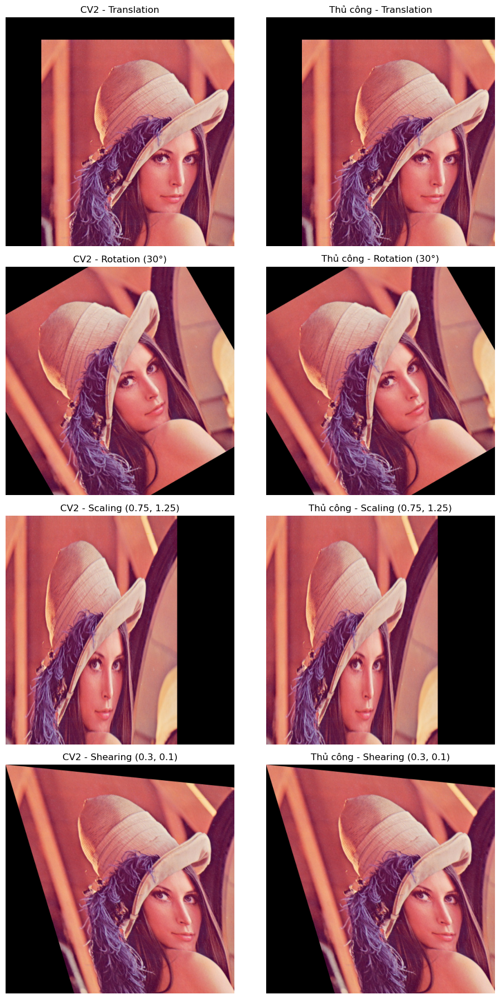

In [38]:
h, w = img.shape[:2]
dsize = (w, h)

# 1. Translation (Tịnh tiến): dịch sang phải tx=80, xuống dưới ty=50
tx, ty = 80, 50
M_translate = np.array([
    [1, 0, tx],
    [0, 1, ty]
], dtype=np.float32)

cv_trans = cv2.warpAffine(img, M_translate, dsize)
manual_trans = warp_affine_manual(img, M_translate, dsize, interpolation='bilinear')

# 2. Rotation (Xoay quanh tâm ảnh góc 30 độ, tỉ lệ 1.0)
angle = 30
cx, cy = w / 2.0, h / 2.0
theta = np.deg2rad(angle)
cos_t, sin_t = np.cos(theta), np.sin(theta)
# Ma trận xoay quanh tâm (cx, cy) theo quy ước tọa độ ảnh của OpenCV
M_rotate_manual = np.array([
    [cos_t, sin_t, (1 - cos_t) * cx - sin_t * cy],
    [-sin_t, cos_t, sin_t * cx + (1 - cos_t) * cy]
], dtype=np.float32)
M_rotate_cv = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)

cv_rot = cv2.warpAffine(img, M_rotate_cv, dsize)
manual_rot = warp_affine_manual(img, M_rotate_manual, dsize, interpolation='bilinear')

# 3. Scaling (Co giãn): sx=0.75, sy=1.25
sx, sy = 0.75, 1.25
M_scale = np.array([
    [sx, 0, 0],
    [0, sy, 0]
], dtype=np.float32)

cv_scale = cv2.warpAffine(img, M_scale, dsize)
manual_scale = warp_affine_manual(img, M_scale, dsize, interpolation='bilinear')

# 4. Shearing (Biến dạng nghiêng): shx=0.3, shy=0.1
shx, shy = 0.3, 0.1
M_shear = np.array([
    [1, shx, 0],
    [shy, 1, 0]
], dtype=np.float32)

cv_shear = cv2.warpAffine(img, M_shear, dsize)
manual_shear = warp_affine_manual(img, M_shear, dsize, interpolation='bilinear')

# Hiển thị so sánh CV2 vs Thủ công cho cả 4 phép biến đổi
transforms = [
    ('Translation', cv_trans, manual_trans),
    ('Rotation (30°)', cv_rot, manual_rot),
    ('Scaling (0.75, 1.25)', cv_scale, manual_scale),
    ('Shearing (0.3, 0.1)', cv_shear, manual_shear),
]

fig, axes = plt.subplots(4, 2, figsize=(10, 18))
for row, (name, cv_res, man_res) in enumerate(transforms):
    axes[row, 0].imshow(cv_res)
    axes[row, 0].set_title(f'CV2 - {name}')
    axes[row, 0].axis('off')
    axes[row, 1].imshow(man_res)
    axes[row, 1].set_title(f'Thủ công - {name}')
    axes[row, 1].axis('off')
plt.tight_layout()
plt.show()

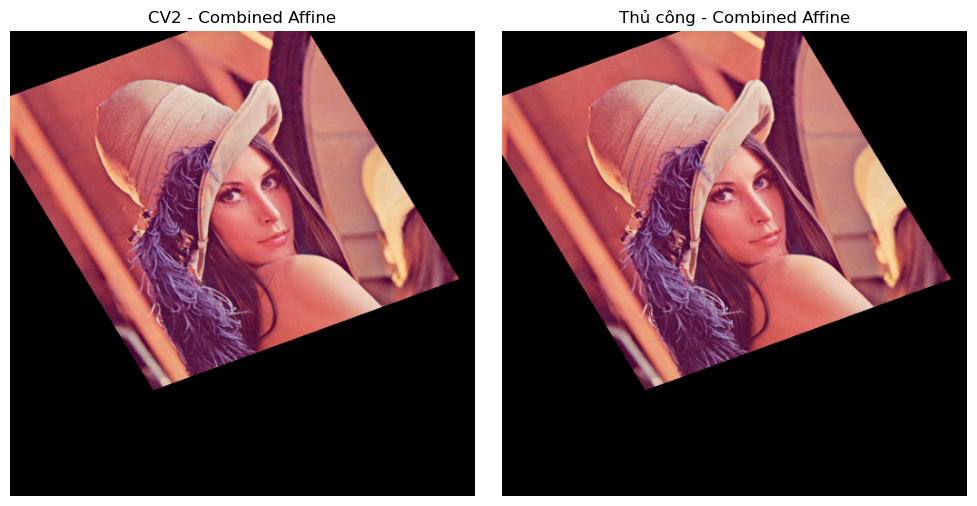

In [39]:
# (Mở rộng) Kết hợp nhiều phép biến đổi Affine bằng phép nhân ma trận đồng nhất 3x3
# Ví dụ: Scale (0.7) -> Shear (shx=0.2) -> Rotate (20°) quanh tâm -> Translate (+40, -20)
def to_3x3(M_2x3):
    return np.vstack([M_2x3, [0, 0, 1]])

M_s = to_3x3(np.array([[0.7, 0, 0], [0, 0.7, 0]], dtype=np.float32))
M_sh = to_3x3(np.array([[1, 0.2, 0], [0, 1, 0]], dtype=np.float32))
M_r = to_3x3(cv2.getRotationMatrix2D((w / 2.0, h / 2.0), 20, 1.0))
M_t = to_3x3(np.array([[1, 0, 40], [0, 1, -20]], dtype=np.float32))

M_combined = (M_t @ M_r @ M_sh @ M_s)[:2, :]

cv_combined = cv2.warpAffine(img, M_combined, dsize)
manual_combined = warp_affine_manual(img, M_combined, dsize, interpolation='bilinear')

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv_combined); axes[0].set_title('CV2 - Combined Affine'); axes[0].axis('off')
axes[1].imshow(manual_combined); axes[1].set_title('Thủ công - Combined Affine'); axes[1].axis('off')
plt.tight_layout()
plt.show()

## 3. Image Smoothing Algorithms

### 3.1 Mean Filter, Gaussian Filter và Median Filter

- **Mean Filter (Box Blur)**: Lấy trung bình cộng các pixel trong cửa sổ $k \times k$.
- **Gaussian Filter**: Lấy trung bình có trọng số theo phân phối chuẩn 2D $G(x, y) = \frac{1}{2\pi\sigma^2} e^{-\frac{x^2+y^2}{2\sigma^2}}$, giúp làm mượt tự nhiên và giữ biên tốt hơn Mean Filter.
- **Median Filter**: Lấy giá trị trung vị trong cửa sổ $k \times k$, cực kỳ hiệu quả để khử **nhiễu muối tiêu (Salt & Pepper noise)** mà vẫn giữ sắc nét biên.

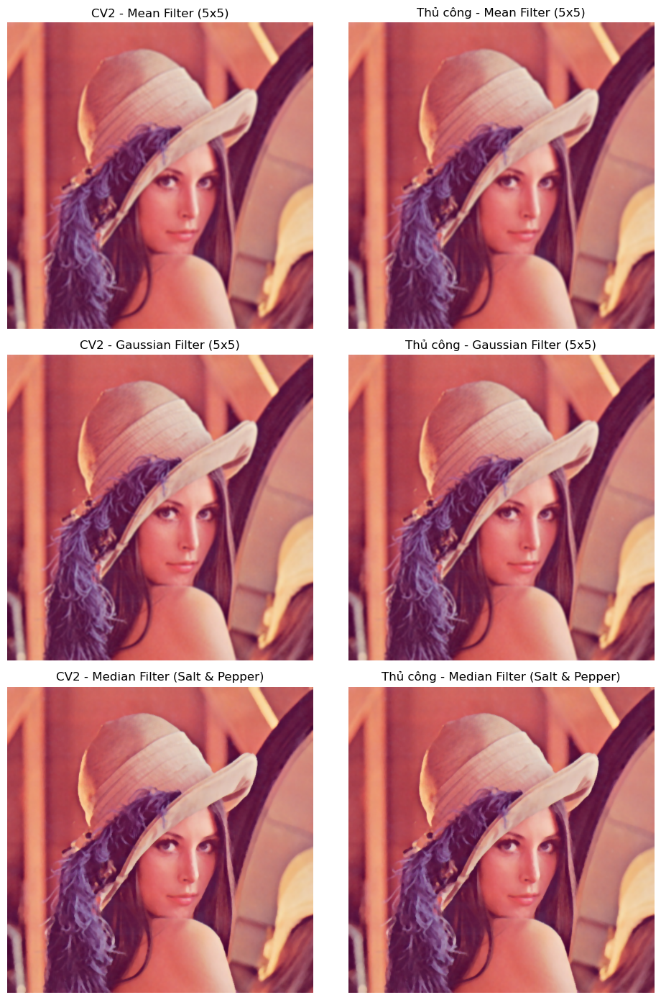

In [40]:
from numpy.lib.stride_tricks import sliding_window_view

# Hàm tích chập 2D tổng quát (hỗ trợ ảnh 2D grayscale và 3D RGB)
def convolve2d_manual(image, kernel, pad_mode='reflect'):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    kernel_flip = np.flip(kernel).astype(np.float32)

    if image.ndim == 2:
        padded = np.pad(image.astype(np.float32), ((ph, ph), (pw, pw)), mode=pad_mode)
        windows = sliding_window_view(padded, (kh, kw))
        return np.einsum('ijkl,kl->ij', windows, kernel_flip)
    else:
        padded = np.pad(image.astype(np.float32), ((ph, ph), (pw, pw), (0, 0)), mode=pad_mode)
        windows = sliding_window_view(padded, (kh, kw), axis=(0, 1))
        return np.einsum('ijckl,kl->ijc', windows, kernel_flip)

def gaussian_kernel(ksize, sigma):
    ax = np.arange(-(ksize // 2), ksize // 2 + 1, dtype=np.float32)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)

def median_filter_manual(image, ksize=5, pad_mode='reflect'):
    p = ksize // 2
    if image.ndim == 2:
        padded = np.pad(image, ((p, p), (p, p)), mode=pad_mode)
        windows = sliding_window_view(padded, (ksize, ksize))
        return np.median(windows, axis=(-2, -1)).astype(image.dtype)
    else:
        padded = np.pad(image, ((p, p), (p, p), (0, 0)), mode=pad_mode)
        windows = sliding_window_view(padded, (ksize, ksize), axis=(0, 1))
        return np.median(windows, axis=(-2, -1)).astype(image.dtype)

# 1. Mean Filter (5x5)
k_mean = np.ones((5, 5), dtype=np.float32) / 25.0
cv_mean = cv2.blur(img, (5, 5))
manual_mean = np.clip(np.round(convolve2d_manual(img, k_mean)), 0, 255).astype(np.uint8)

# 2. Gaussian Filter (5x5, sigma=1.5)
k_gauss = gaussian_kernel(5, sigma=1.5)
cv_gauss = cv2.GaussianBlur(img, (5, 5), sigmaX=1.5)
manual_gauss = np.clip(np.round(convolve2d_manual(img, k_gauss)), 0, 255).astype(np.uint8)

# 3. Tạo ảnh nhiễu muối tiêu (Salt & Pepper) để kiểm thử Median Filter (5x5)
rng = np.random.default_rng(42)
img_sp = img.copy()
prob = 0.05
rand_map = rng.random(img.shape[:2])
img_sp[rand_map < prob / 2] = 0
img_sp[(rand_map >= prob / 2) & (rand_map < prob)] = 255

cv_median = cv2.medianBlur(img_sp, 5)
manual_median = median_filter_manual(img_sp, 5)

fig, axes = plt.subplots(3, 2, figsize=(10, 14))
axes[0, 0].imshow(cv_mean); axes[0, 0].set_title('CV2 - Mean Filter (5x5)'); axes[0, 0].axis('off')
axes[0, 1].imshow(manual_mean); axes[0, 1].set_title('Thủ công - Mean Filter (5x5)'); axes[0, 1].axis('off')
axes[1, 0].imshow(cv_gauss); axes[1, 0].set_title('CV2 - Gaussian Filter (5x5)'); axes[1, 0].axis('off')
axes[1, 1].imshow(manual_gauss); axes[1, 1].set_title('Thủ công - Gaussian Filter (5x5)'); axes[1, 1].axis('off')
axes[2, 0].imshow(cv_median); axes[2, 0].set_title('CV2 - Median Filter (Salt & Pepper)'); axes[2, 0].axis('off')
axes[2, 1].imshow(manual_median); axes[2, 1].set_title('Thủ công - Median Filter (Salt & Pepper)'); axes[2, 1].axis('off')
plt.tight_layout()
plt.show()

## 4. Edge Detection Algorithms

### 4.1 Sobel, Laplacian và Canny Edge Detection

- **Sobel**: Tính gradient bậc 1 theo trục $x$ ($G_x$) và trục $y$ ($G_y$), độ lớn biên $G = \sqrt{G_x^2 + G_y^2}$.
- **Laplacian**: Tính đạo hàm bậc 2 ($\nabla^2 f$), nhạy với các điểm thay đổi cường độ đột ngột.
- **Canny**: Thuật toán phát hiện biên nhiều bước: (1) Gaussian Blur $\rightarrow$ (2) Gradient Sobel $\rightarrow$ (3) Non-Maximum Suppression $\rightarrow$ (4) Double Thresholding & Hysteresis.

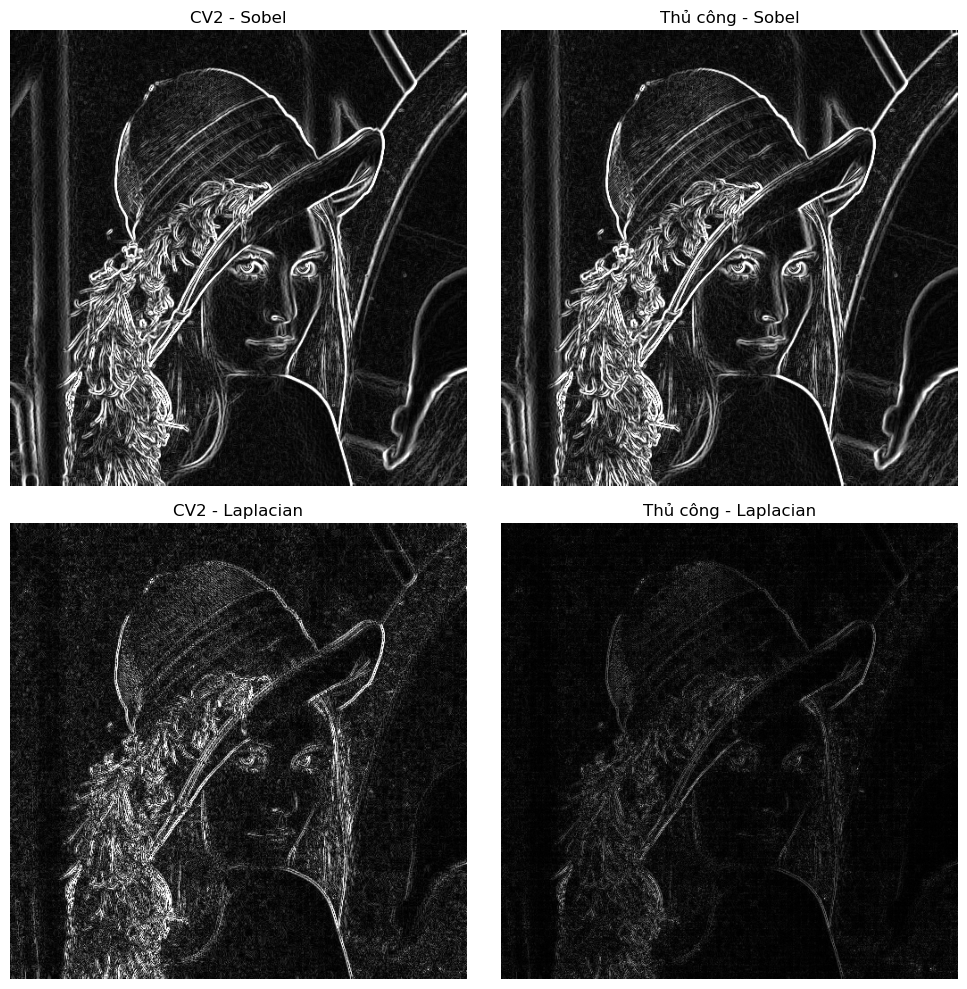

In [41]:
img_gray_edge = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

# 1. Sobel Edge Detection
Gx_kernel = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
Gy_kernel = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)

# Thủ công (lưu ý: convolve2d_manual lật kernel nên truyền -kernel để khớp phép correlation của Sobel)
man_gx = convolve2d_manual(img_gray_edge, np.flip(Gx_kernel))
man_gy = convolve2d_manual(img_gray_edge, np.flip(Gy_kernel))
manual_sobel = np.clip(np.hypot(man_gx, man_gy), 0, 255).astype(np.uint8)

# OpenCV
cv_gx = cv2.Sobel(img_gray_edge, cv2.CV_64F, 1, 0, ksize=3)
cv_gy = cv2.Sobel(img_gray_edge, cv2.CV_64F, 0, 1, ksize=3)
cv_sobel = np.clip(np.hypot(cv_gx, cv_gy), 0, 255).astype(np.uint8)

# 2. Laplacian Edge Detection
L_kernel = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
manual_lap = np.clip(np.abs(convolve2d_manual(img_gray_edge, L_kernel)), 0, 255).astype(np.uint8)
cv_lap = np.clip(np.abs(cv2.Laplacian(img_gray_edge, cv2.CV_64F, ksize=3)), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes[0, 0].imshow(cv_sobel, cmap='gray'); axes[0, 0].set_title('CV2 - Sobel'); axes[0, 0].axis('off')
axes[0, 1].imshow(manual_sobel, cmap='gray'); axes[0, 1].set_title('Thủ công - Sobel'); axes[0, 1].axis('off')
axes[1, 0].imshow(cv_lap, cmap='gray'); axes[1, 0].set_title('CV2 - Laplacian'); axes[1, 0].axis('off')
axes[1, 1].imshow(manual_lap, cmap='gray'); axes[1, 1].set_title('Thủ công - Laplacian'); axes[1, 1].axis('off')
plt.tight_layout()
plt.show()

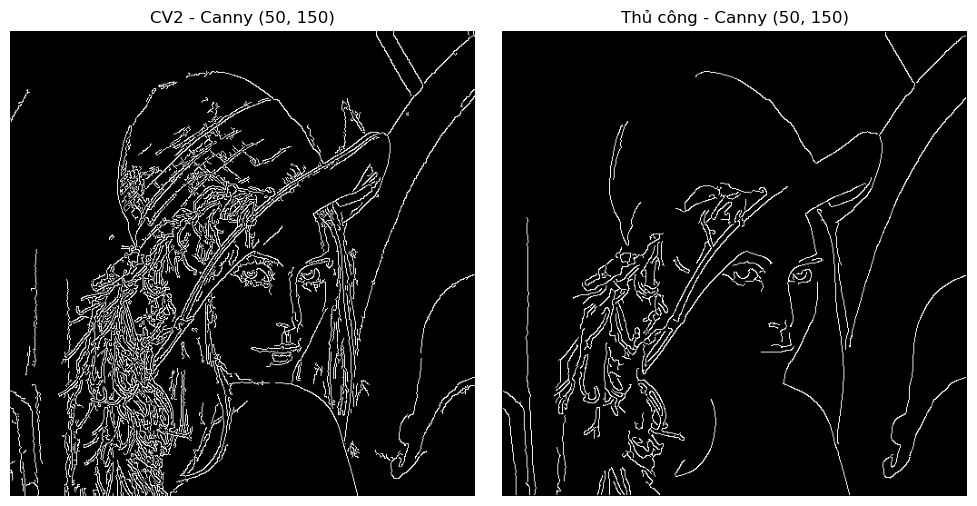

In [42]:
# 3. Canny Edge Detection (Thủ công vs OpenCV)
def canny_manual(image_gray, low_thresh=50, high_thresh=150, sigma=1.4):
    # Bước 1: Làm mượt bằng Gaussian 5x5
    smoothed = convolve2d_manual(image_gray, gaussian_kernel(5, sigma))

    # Bước 2: Tính Gradient Magnitude & Angle bằng Sobel
    gx = convolve2d_manual(smoothed, np.flip(Gx_kernel))
    gy = convolve2d_manual(smoothed, np.flip(Gy_kernel))
    mag = np.hypot(gx, gy)
    angle = np.rad2deg(np.arctan2(gy, gx)) % 180.0

    # Bước 3: Non-Maximum Suppression (NMS)
    H, W = mag.shape
    nms = np.zeros_like(mag)
    q = np.zeros_like(mag)
    r = np.zeros_like(mag)

    # Lượng tử hóa góc thành 4 hướng: 0, 45, 90, 135
    dir0 = (angle < 22.5) | (angle >= 157.5)
    dir45 = (angle >= 22.5) & (angle < 67.5)
    dir90 = (angle >= 67.5) & (angle < 112.5)
    dir135 = (angle >= 112.5) & (angle < 157.5)

    # Hướng 0° (trái - phải)
    q[1:-1, 1:-1] = np.where(dir0[1:-1, 1:-1], mag[1:-1, 2:], q[1:-1, 1:-1])
    r[1:-1, 1:-1] = np.where(dir0[1:-1, 1:-1], mag[1:-1, :-2], r[1:-1, 1:-1])
    # Hướng 45° (chéo)
    q[1:-1, 1:-1] = np.where(dir45[1:-1, 1:-1], mag[2:, 2:], q[1:-1, 1:-1])
    r[1:-1, 1:-1] = np.where(dir45[1:-1, 1:-1], mag[:-2, :-2], r[1:-1, 1:-1])
    # Hướng 90° (trên - dưới)
    q[1:-1, 1:-1] = np.where(dir90[1:-1, 1:-1], mag[2:, 1:-1], q[1:-1, 1:-1])
    r[1:-1, 1:-1] = np.where(dir90[1:-1, 1:-1], mag[:-2, 1:-1], r[1:-1, 1:-1])
    # Hướng 135° (chéo)
    q[1:-1, 1:-1] = np.where(dir135[1:-1, 1:-1], mag[:-2, 2:], q[1:-1, 1:-1])
    r[1:-1, 1:-1] = np.where(dir135[1:-1, 1:-1], mag[2:, :-2], r[1:-1, 1:-1])

    is_max = (mag >= q) & (mag >= r)
    nms[1:-1, 1:-1] = np.where(is_max[1:-1, 1:-1], mag[1:-1, 1:-1], 0)

    # Bước 4: Double Thresholding & Hysteresis
    strong = nms >= high_thresh
    weak = (nms >= low_thresh) & (nms < high_thresh)
    edges = strong.copy()

    # Lan truyền từ biên mạnh sang biên yếu lân cận 8-hướng
    changed = True
    while changed:
        padded_e = np.pad(edges, 1, mode='constant', constant_values=False)
        has_strong_neighbor = (
            padded_e[:-2, :-2] | padded_e[:-2, 1:-1] | padded_e[:-2, 2:] |
            padded_e[1:-1, :-2] | padded_e[1:-1, 2:] |
            padded_e[2:, :-2] | padded_e[2:, 1:-1] | padded_e[2:, 2:]
        )
        new_edges = edges | (weak & has_strong_neighbor)
        changed = not np.array_equal(new_edges, edges)
        edges = new_edges

    return (edges.astype(np.uint8) * 255)

cv_canny = cv2.Canny(img_gray_edge, 50, 150)
manual_canny = canny_manual(img_gray_edge, 50, 150)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv_canny, cmap='gray'); axes[0].set_title('CV2 - Canny (50, 150)'); axes[0].axis('off')
axes[1].imshow(manual_canny, cmap='gray'); axes[1].set_title('Thủ công - Canny (50, 150)'); axes[1].axis('off')
plt.tight_layout()
plt.show()

## 5. Tổng hợp so sánh: Tự cài đặt (NumPy) vs Thư viện OpenCV (`cv2`)

### 5.1 So sánh độ chính xác (MSE, PSNR, Max Diff) và thời gian thực thi (ms)

- **MSE (Mean Squared Error)**: Càng gần `0` thì kết quả tự cài đặt càng giống `cv2`.
- **PSNR (Peak Signal-to-Noise Ratio)**: Càng cao (hoặc `inf` nếu MSE = 0) thì độ tương đồng càng lớn.
- **Max Abs Diff**: Sai lệch cường độ pixel lớn nhất giữa 2 kết quả.
- **Thời gian chạy (ms)**: So sánh tốc độ thực thi giữa C/C++ tối ưu trong `cv2` và mã `numpy` tự cài đặt.

In [43]:
import time

def compute_metrics(img_cv, img_man):
    a = img_cv.astype(np.float64)
    b = img_man.astype(np.float64)
    diff = np.abs(a - b)
    mse = np.mean(diff ** 2)
    max_diff = np.max(diff)
    psnr = float('inf') if mse == 0 else 10.0 * np.log10((255.0 ** 2) / mse)
    return mse, psnr, max_diff

def benchmark(fn, repeats=3):
    start = time.perf_counter()
    res = None
    for _ in range(repeats):
        res = fn()
    elapsed_ms = (time.perf_counter() - start) * 1000.0 / repeats
    return res, elapsed_ms

# Chuẩn bị dữ liệu & các phép biến đổi cần so sánh
img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
gray_for_cmp = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
lut_log = np.clip((255.0 / np.log(1 + np.max(img.astype(np.float32)))) * np.log(1 + np.arange(256, dtype=np.float32)), 0, 255).astype(np.uint8)

def manual_hist_eq(g):
    hist = np.bincount(g.flatten(), minlength=256)
    cdf = np.cumsum(hist)
    mapping = np.round(255 * cdf / g.size).astype(np.uint8)
    return mapping[g]

comparisons = [
    ('Color: BGR -> RGB',
     lambda: cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB),
     lambda: img_bgr[:, :, [2, 1, 0]]),
    ('Color: Brightness/Contrast',
     lambda: cv2.convertScaleAbs(img, alpha=1.3, beta=10),
     lambda: np.clip(img.astype(np.float32) * 1.3 + 10, 0, 255).astype(np.uint8)),
    ('Color: Log Transform',
     lambda: cv2.LUT(img, lut_log),
     lambda: np.clip((255.0 / np.log(1 + np.max(img.astype(np.float32)))) * np.log(1 + img.astype(np.float32)), 0, 255).astype(np.uint8)),
    ('Color: Hist Equalization',
     lambda: cv2.equalizeHist(gray_for_cmp),
     lambda: manual_hist_eq(gray_for_cmp)),
    ('Interp: Nearest-Neighbor (5x)',
     lambda: cv2.resize(crop, (new_w, new_h), interpolation=cv2.INTER_NEAREST),
     lambda: nearest_neighbor_resize(crop, new_h, new_w)),
    ('Interp: Bilinear (5x)',
     lambda: cv2.resize(crop, (new_w, new_h), interpolation=cv2.INTER_LINEAR),
     lambda: bilinear_resize(crop, new_h, new_w)),
    ('Affine: Translation',
     lambda: cv2.warpAffine(img, M_translate, dsize),
     lambda: warp_affine_manual(img, M_translate, dsize, interpolation='bilinear')),
    ('Affine: Rotation (30°)',
     lambda: cv2.warpAffine(img, M_rotate_cv, dsize),
     lambda: warp_affine_manual(img, M_rotate_manual, dsize, interpolation='bilinear')),
    ('Affine: Scaling',
     lambda: cv2.warpAffine(img, M_scale, dsize),
     lambda: warp_affine_manual(img, M_scale, dsize, interpolation='bilinear')),
    ('Affine: Shearing',
     lambda: cv2.warpAffine(img, M_shear, dsize),
     lambda: warp_affine_manual(img, M_shear, dsize, interpolation='bilinear')),
    ('Smooth: Mean (5x5)',
     lambda: cv2.blur(img, (5, 5)),
     lambda: np.clip(np.round(convolve2d_manual(img, k_mean)), 0, 255).astype(np.uint8)),
    ('Smooth: Gaussian (5x5)',
     lambda: cv2.GaussianBlur(img, (5, 5), sigmaX=1.5),
     lambda: np.clip(np.round(convolve2d_manual(img, k_gauss)), 0, 255).astype(np.uint8)),
    ('Smooth: Median (5x5)',
     lambda: cv2.medianBlur(img_sp, 5),
     lambda: median_filter_manual(img_sp, 5)),
    ('Edge: Sobel',
     lambda: np.clip(np.hypot(cv2.Sobel(gray_for_cmp, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(gray_for_cmp, cv2.CV_64F, 0, 1, ksize=3)), 0, 255).astype(np.uint8),
     lambda: np.clip(np.hypot(convolve2d_manual(gray_for_cmp, np.flip(Gx_kernel)), convolve2d_manual(gray_for_cmp, np.flip(Gy_kernel))), 0, 255).astype(np.uint8)),
    ('Edge: Laplacian',
     lambda: np.clip(np.abs(cv2.Laplacian(gray_for_cmp, cv2.CV_64F, ksize=3)), 0, 255).astype(np.uint8),
     lambda: np.clip(np.abs(convolve2d_manual(gray_for_cmp, L_kernel)), 0, 255).astype(np.uint8)),
    ('Edge: Canny',
     lambda: cv2.Canny(gray_for_cmp, 50, 150),
     lambda: canny_manual(gray_for_cmp, 50, 150)),
]

results = []
print(f"{'Thuật toán':<30} | {'MSE':>10} | {'PSNR (dB)':>10} | {'MaxDiff':>8} | {'CV2 (ms)':>9} | {'Manual (ms)':>11}")
print('-' * 92)
for name, fn_cv, fn_man in comparisons:
    out_cv, t_cv = benchmark(fn_cv)
    out_man, t_man = benchmark(fn_man)
    mse, psnr, max_d = compute_metrics(out_cv, out_man)
    psnr_str = 'inf' if np.isinf(psnr) else f'{psnr:.2f}'
    print(f'{name:<30} | {mse:10.4f} | {psnr_str:>10} | {max_d:8.1f} | {t_cv:9.2f} | {t_man:11.2f}')
    results.append((name, mse, psnr, max_d, t_cv, t_man, out_cv, out_man))

Thuật toán                     |        MSE |  PSNR (dB) |  MaxDiff |  CV2 (ms) | Manual (ms)
--------------------------------------------------------------------------------------------
Color: BGR -> RGB              |     0.0000 |        inf |      0.0 |      0.14 |        0.32
Color: Brightness/Contrast     |     0.3639 |      52.52 |      1.0 |      0.30 |        1.72
Color: Log Transform           |     0.0000 |        inf |      0.0 |      0.37 |        3.20
Color: Hist Equalization       |     0.0000 |        inf |      0.0 |      0.29 |        1.22
Interp: Nearest-Neighbor (5x)  |     0.0000 |        inf |      0.0 |      0.36 |        0.93
Interp: Bilinear (5x)          |     0.0998 |      58.14 |      1.0 |      0.22 |        8.63
Affine: Translation            |     0.0000 |        inf |      0.0 |      0.39 |       45.07
Affine: Rotation (30°)         |     0.0001 |      87.45 |      1.0 |      0.66 |       49.06
Affine: Scaling                |     0.0000 |        inf |   

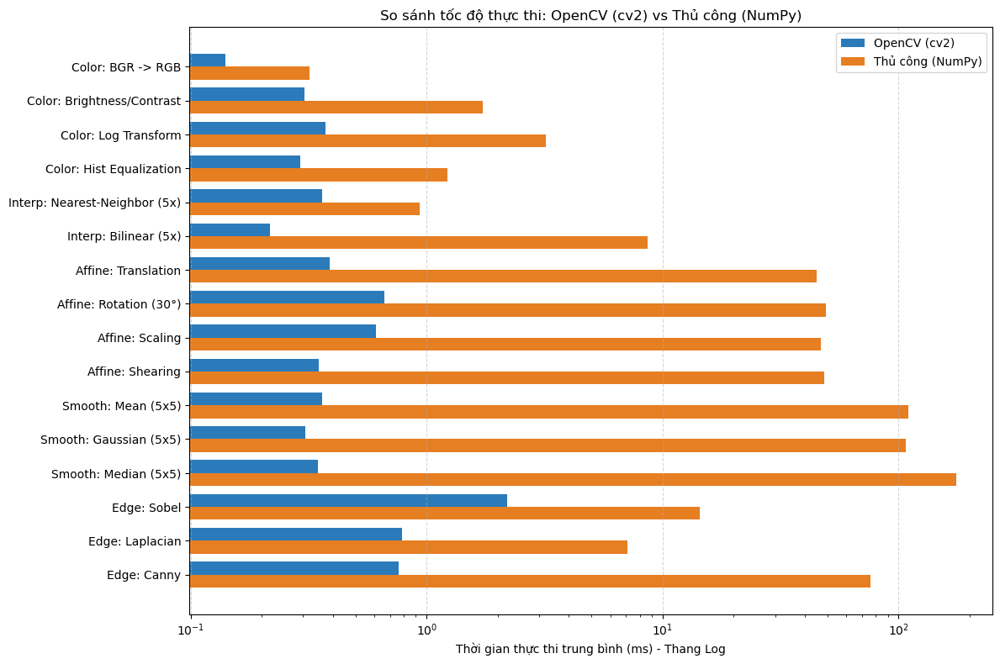

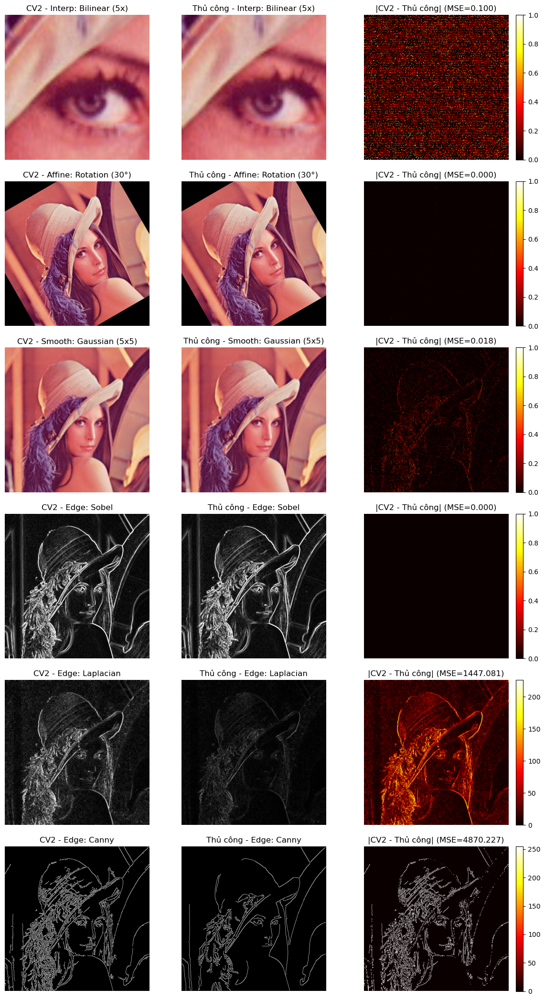

In [44]:
# 5.2 Biểu đồ so sánh thời gian thực thi (CV2 vs Thủ công)
names = [r[0] for r in results]
times_cv = [r[4] for r in results]
times_man = [r[5] for r in results]

y_pos = np.arange(len(names))
height = 0.38

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(y_pos - height / 2, times_cv, height, label='OpenCV (cv2)', color='#2b7bba')
ax.barh(y_pos + height / 2, times_man, height, label='Thủ công (NumPy)', color='#e67e22')
ax.set_yticks(y_pos)
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.set_xscale('log')
ax.set_xlabel('Thời gian thực thi trung bình (ms) - Thang Log')
ax.set_title('So sánh tốc độ thực thi: OpenCV (cv2) vs Thủ công (NumPy)')
ax.legend()
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# 5.3 Bản đồ sai khác (Difference Map) cho một số phép biến đổi tiêu biểu
sample_indices = [5, 7, 11, 13, 14, 15]  # Bilinear, Rotation, Gaussian, Sobel, Laplacian, Canny
fig, axes = plt.subplots(len(sample_indices), 3, figsize=(12, 3.5 * len(sample_indices)))
for row, idx in enumerate(sample_indices):
    name, mse, psnr, max_d, _, _, out_cv, out_man = results[idx]
    diff_map = np.abs(out_cv.astype(np.float32) - out_man.astype(np.float32))
    if diff_map.ndim == 3:
        diff_gray = np.mean(diff_map, axis=2)
    else:
        diff_gray = diff_map

    cmap_choice = 'gray' if out_cv.ndim == 2 else None
    axes[row, 0].imshow(out_cv, cmap=cmap_choice); axes[row, 0].set_title(f'CV2 - {name}'); axes[row, 0].axis('off')
    axes[row, 1].imshow(out_man, cmap=cmap_choice); axes[row, 1].set_title(f'Thủ công - {name}'); axes[row, 1].axis('off')
    im = axes[row, 2].imshow(diff_gray, cmap='hot', vmin=0, vmax=max(1.0, np.max(diff_gray)))
    axes[row, 2].set_title(f'|CV2 - Thủ công| (MSE={mse:.3f})'); axes[row, 2].axis('off')
    fig.colorbar(im, ax=axes[row, 2], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()